# Rossmann Store Sales – Estimating the Promotion Effect

**Question:** How much do promotions increase daily sales, after controlling for
day of week, season, holidays and differences between stores?

In [1]:
!pip install linearmodels -q

from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
from linearmodels.panel import PanelOLS

DATA_DIR = '/content/drive/MyDrive/rossmann-sales-analysis/data/'
FIG_DIR = '/content/drive/MyDrive/rossmann-sales-analysis/figures/'
df = pd.read_parquet(DATA_DIR + 'train_clean.parquet')

Mounted at /content/drive


In [2]:
# Exclude Sundays: only 33 special stores are open, and promotions never run on Sundays
df = df[df['DayOfWeek'] != 7].copy()

df['log_sales'] = np.log(df['Sales'])
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year

# Panel structure: one row per store and day
panel = df.set_index(['Store', 'Date'])
print(panel.shape)

(840745, 18)


In [3]:
def promo_effect(res, name):
    b = res.params['Promo']
    lo, hi = res.conf_int().loc['Promo']
    pct = lambda x: 100 * (np.exp(x) - 1)
    print(f'{name}: {pct(b):+.1f}%  (95% CI: {pct(lo):+.1f}% to {pct(hi):+.1f}%)')

In [4]:
controls = 'C(DayOfWeek) + C(Month) + C(Year) + C(StateHoliday) + SchoolHoliday'

# Model 1: naive comparison
m1 = PanelOLS.from_formula('log_sales ~ 1 + Promo', data=panel)
res1 = m1.fit(cov_type='clustered', cluster_entity=True)

# Model 2: add time and holiday controls
m2 = PanelOLS.from_formula(f'log_sales ~ 1 + Promo + {controls}', data=panel)
res2 = m2.fit(cov_type='clustered', cluster_entity=True)

# Model 3: add store fixed effects
m3 = PanelOLS.from_formula(f'log_sales ~ 1 + Promo + {controls} + EntityEffects', data=panel)
res3 = m3.fit(cov_type='clustered', cluster_entity=True)

promo_effect(res1, 'Model 1 (naive)          ')
promo_effect(res2, 'Model 2 (+ time controls)')
promo_effect(res3, 'Model 3 (+ store FE)     ')

Model 1 (naive)          : +41.5%  (95% CI: +40.4% to +42.6%)
Model 2 (+ time controls): +39.3%  (95% CI: +38.6% to +40.1%)
Model 3 (+ store FE)     : +39.3%  (95% CI: +38.6% to +40.0%)


In [5]:
# For each date: do all stores have the same Promo value?
promo_per_date = df.groupby('Date')['Promo'].nunique()
print('Dates where stores differ in Promo:', (promo_per_date > 1).sum(), 'of', len(promo_per_date))

Dates where stores differ in Promo: 0 of 808


In [6]:
days = {1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri'}
for d, name in days.items():
    panel[f'Promo_{name}'] = ((panel['Promo'] == 1) & (panel['DayOfWeek'] == d)).astype(int)

promo_terms = ' + '.join(f'Promo_{n}' for n in days.values())
m4 = PanelOLS.from_formula(f'log_sales ~ 1 + {promo_terms} + {controls} + EntityEffects', data=panel)
res4 = m4.fit(cov_type='clustered', cluster_entity=True)

pct = lambda x: 100 * (np.exp(x) - 1)
ci = res4.conf_int()
for n in days.values():
    v = f'Promo_{n}'
    print(f'{n}: {pct(res4.params[v]):+.1f}%  '
          f'(95% CI: {pct(ci.loc[v, "lower"]):+.1f}% to {pct(ci.loc[v, "upper"]):+.1f}%)')

Mon: +60.8%  (95% CI: +59.5% to +62.2%)
Tue: +47.5%  (95% CI: +46.7% to +48.4%)
Wed: +37.2%  (95% CI: +36.6% to +37.9%)
Thu: +31.3%  (95% CI: +30.8% to +31.8%)
Fri: +22.5%  (95% CI: +22.1% to +23.0%)


## Results: average promotion effect

| Model | Controls | Promo effect | 95% CI |
|---|---|---|---|
| 1 | none | +41.5% | +40.4% to +42.6% |
| 2 | day of week, month, year, holidays | +39.3% | +38.6% to +40.1% |
| 3 | + store fixed effects | +39.3% | +38.6% to +40.0% |
| 3 | two-way clustered SE (store and date) | +39.3% | +37.0% to +41.6% |

Because promotions vary by date, not by store, standard errors are clustered by both store and date. This widens the confidence interval about threefold, but the effect remains large and clearly positive.


Controlling for time reduces the estimate, as expected from the Saturday confounding found
in the EDA. Store fixed effects do not change it, because promotions are scheduled
chain-wide: on every date, all stores have the same promo status (checked for all 808 dates).

## Results: promotion effect by weekday (Model 4, two-way clustered SE)

| Day | Promo effect | 95% CI |
|---|---|---|
| Mon | +60.8% | +55.3% to +66.5% |
| Tue | +47.5% | +42.6% to +52.7% |
| Wed | +37.2% | +32.8% to +41.8% |
| Thu | +31.3% | +27.6% to +35.1% |
| Fri | +22.5% | +18.8% to +26.4% |

The promo effect decreases steadily during the week. A Wald test confirms that the Monday effect is larger than the Friday effect
(χ² = 130.2, p < 0.001). Neighbouring days are not all clearly
different (the Wednesday and Thursday intervals overlap), but the overall downward trend
is clear. Possible explanation: promotions start on Mondays and customers react early
in the promo period.

## Limitations

- Promotions were not randomly assigned. Because they are scheduled chain-wide, the
  estimate is identified only by comparing promo days with non-promo days. Anything else
  happening chain-wide on promo days (e.g. advertising) is included in the "promo" effect.
- The model measures higher sales on promo days. It cannot tell whether promotions create
  additional sales or partly shift purchases from other days (pull-forward effect).
- Sundays were excluded (only 33 special stores open, no promotions on Sundays).

In [7]:
res3_tw = m3.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
promo_effect(res3_tw, 'Model 3 (two-way clustered)')

Model 3 (two-way clustered): +39.3%  (95% CI: +37.0% to +41.6%)


In [8]:
res4_tw = m4.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
ci = res4_tw.conf_int()
for n in days.values():
    v = f'Promo_{n}'
    print(f'{n}: {pct(res4_tw.params[v]):+.1f}%  '
          f'(95% CI: {pct(ci.loc[v, "lower"]):+.1f}% to {pct(ci.loc[v, "upper"]):+.1f}%)')

Mon: +60.8%  (95% CI: +55.3% to +66.5%)
Tue: +47.5%  (95% CI: +42.6% to +52.7%)
Wed: +37.2%  (95% CI: +32.8% to +41.8%)
Thu: +31.3%  (95% CI: +27.6% to +35.1%)
Fri: +22.5%  (95% CI: +18.8% to +26.4%)


In [9]:
print(res4_tw.wald_test(formula='Promo_Mon = Promo_Fri'))

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 130.2207
P-value: 0.0000
Distributed: chi2(1)


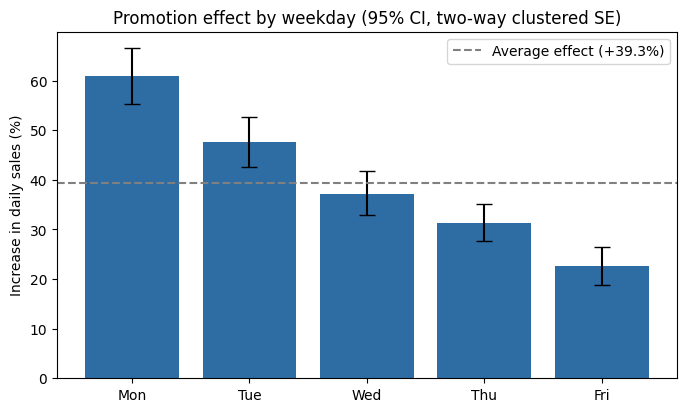

In [10]:
import matplotlib.pyplot as plt

names = list(days.values())
ci = res4_tw.conf_int()
effect = [pct(res4_tw.params[f'Promo_{n}']) for n in names]
lower = [pct(ci.loc[f'Promo_{n}', 'lower']) for n in names]
upper = [pct(ci.loc[f'Promo_{n}', 'upper']) for n in names]
err = [[e - l for e, l in zip(effect, lower)],
       [u - e for e, u in zip(effect, upper)]]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(names, effect, yerr=err, capsize=6, color='#2E6DA4')
ax.axhline(39.3, linestyle='--', color='grey', label='Average effect (+39.3%)')
ax.set_ylabel('Increase in daily sales (%)')
ax.set_title('Promotion effect by weekday (95% CI, two-way clustered SE)')
ax.legend()
plt.savefig(FIG_DIR + 'promo_effect_by_weekday.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
import sys, pandas, numpy, matplotlib, pyarrow, lightgbm, linearmodels
print('python', sys.version.split()[0])
for m in [pandas, numpy, matplotlib, pyarrow, lightgbm, linearmodels]:
    print(m.__name__, m.__version__)

python 3.13.18
pandas 2.2.3
numpy 2.4.6
matplotlib 3.10.0
pyarrow 23.0.1
lightgbm 4.6.0
linearmodels 7.1
